<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 02 · Band structures, density of states and Fermi levels

**Goals**: k-paths through high-symmetry points, band plots with spin/orbital weights,
DOS and projected DOS, Fermi levels and gaps.

$$g(E)=\frac{1}{N_k}\sum_{n\mathbf k}\delta(E-E_{n\mathbf k}),\qquad
g_\alpha(E)=\frac{1}{N_k}\sum_{n\mathbf k}|\langle\alpha|n\mathbf k\rangle|^2\,\delta(E-E_{n\mathbf k})$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline

## 1. k-paths
Each library model carries `special_points` and a default path. Paths can mix labels and coordinates, and `'|'` breaks a path.

In [2]:
g = M.honeycomb()
print(g.special_points)
path = hf.kpath(g, ["G", "K", "M", "G"], n=300)
print(path.labels, np.round(path.ticks, 3))

{'G': array([0., 0.]), 'K': array([0.66666667, 0.33333333]), "K'": array([0.33333333, 0.66666667]), 'M': array([0.5, 0. ])}
['$\\Gamma$', 'K', 'M', '$\\Gamma$'] [0.    4.189 6.283 9.911]


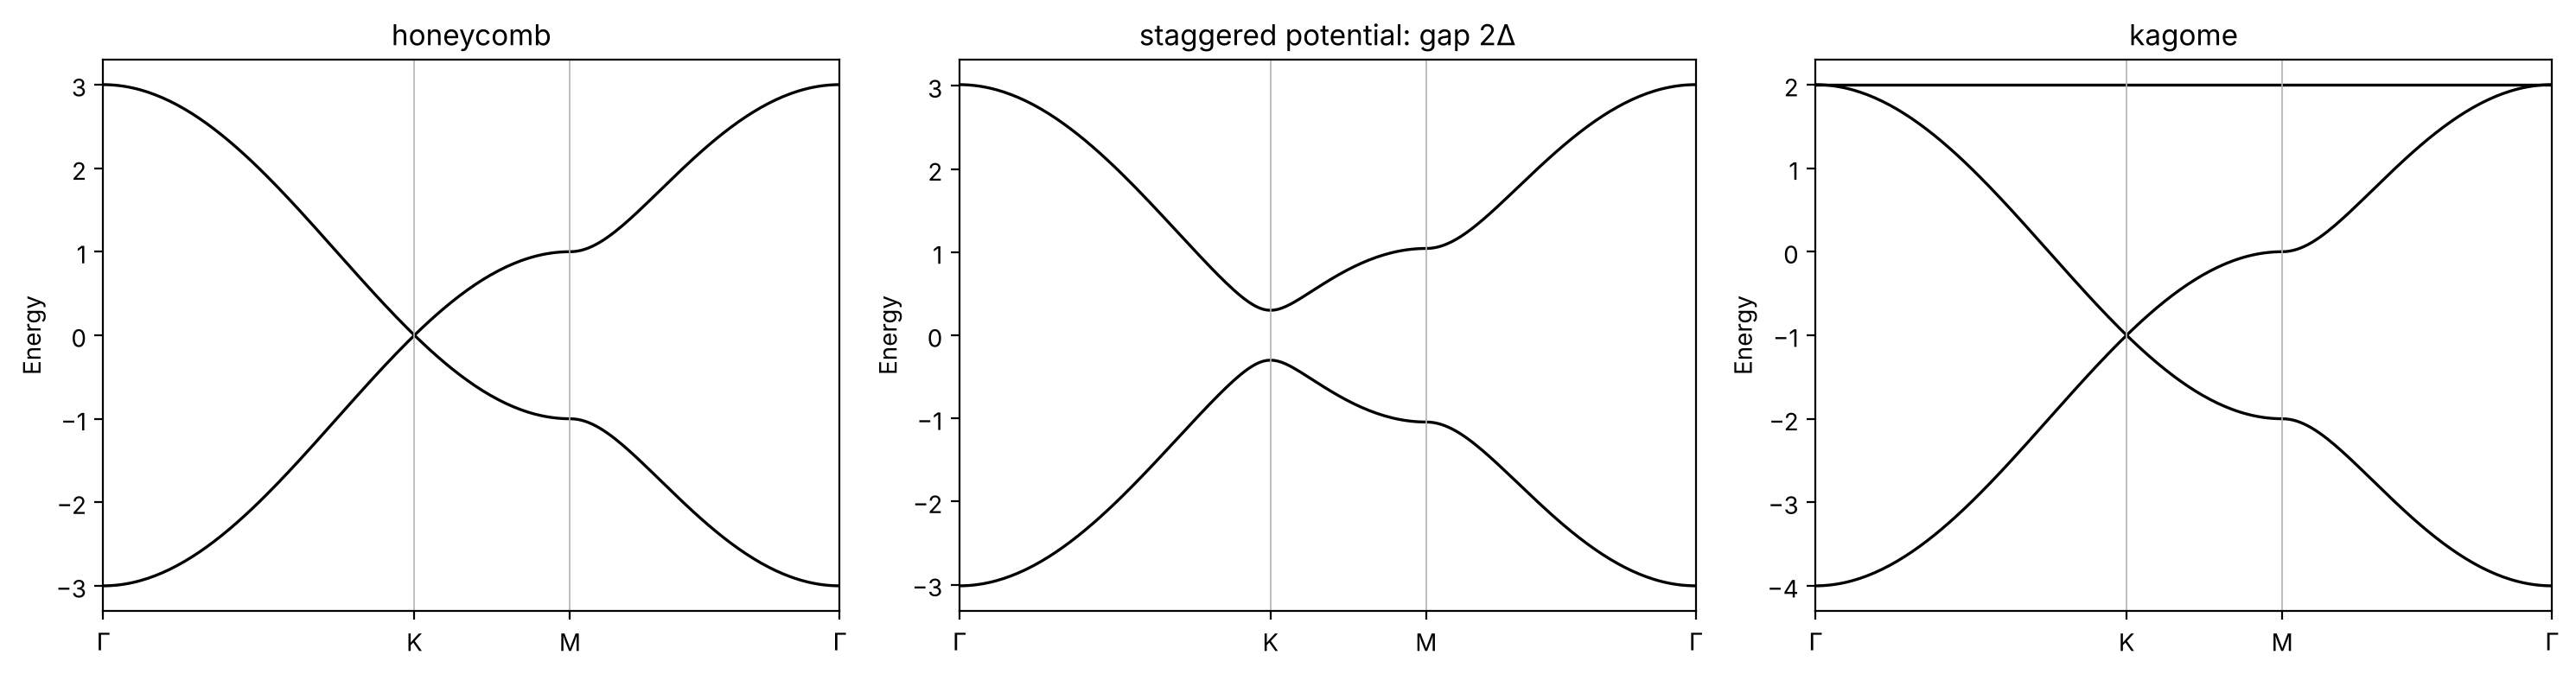

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
M.honeycomb().plot_bands(ax=axes[0])
M.honeycomb(delta=0.3).plot_bands(ax=axes[1], title="staggered potential: gap 2Δ")
M.kagome().plot_bands(ax=axes[2])
plt.tight_layout()

## 2. DOS and projected DOS
Notice the |E| DOS of the Dirac cone, the log van Hove peaks at ±t, and the flat-band delta peak of kagome.

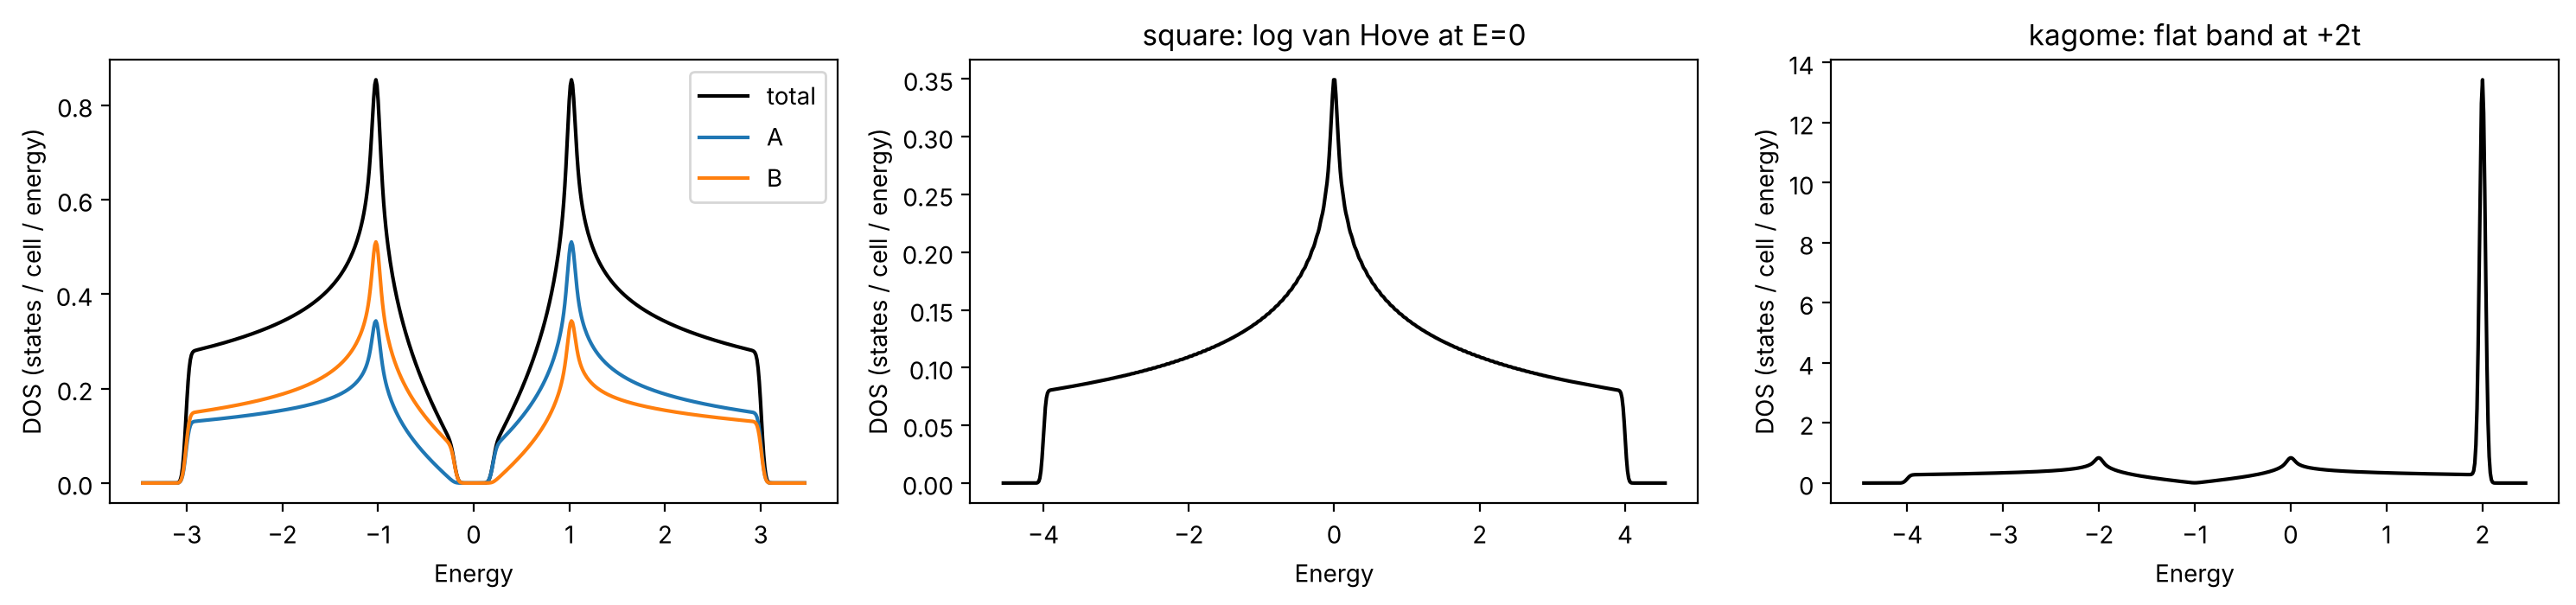

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
hf.plot_dos(hf.dos(M.honeycomb(delta=0.2), nk=150, sigma=0.03, projections={"A": "A", "B": "B"}), ax=axes[0])
hf.plot_dos(hf.dos(M.square(), nk=200, sigma=0.03), ax=axes[1]); axes[1].set_title("square: log van Hove at E=0")
hf.plot_dos(hf.dos(M.kagome(), nk=120, sigma=0.03), ax=axes[2]); axes[2].set_title("kagome: flat band at +2t")
plt.tight_layout()

In [5]:
d = hf.dos(M.honeycomb(), nk=100, sigma=0.05)
print("integral of DOS =", np.trapezoid(d.dos, d.energies) if hasattr(np, 'trapezoid') else np.trapz(d.dos, d.energies), "(number of bands = 2)")

integral of DOS = 2.0 (number of bands = 2)


## 3. Fermi level and gaps

In [6]:
print("graphene E_F at half filling:", round(hf.fermi_level(M.honeycomb(), 1), 4))
print("hBN-like gap (2Δ = 0.6):", round(hf.band_gap(M.honeycomb(delta=0.3), 1, 90), 4))

graphene E_F at half filling: 0.0
hBN-like gap (2Δ = 0.6): 0.6


## 4. Band weights: spin texture of an altermagnet
The d-wave altermagnet has zero net moment but spin-split bands along Γ–X and Γ–Y with *opposite* signs, and no splitting along Γ–M.

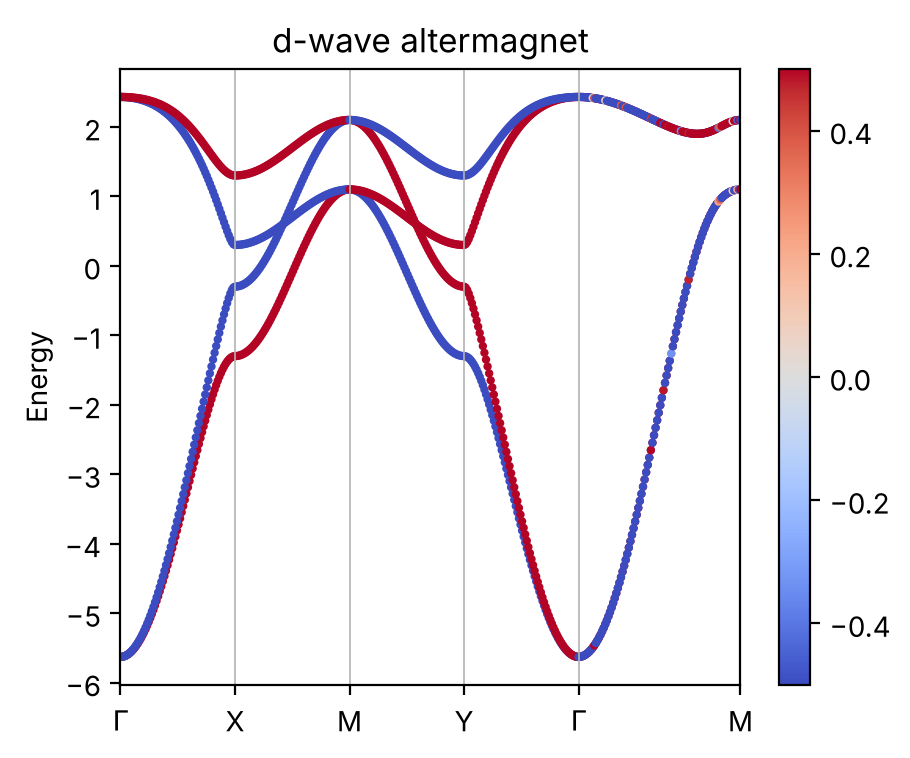

In [7]:
am = M.altermagnet_dwave()
am.plot_bands(weights=am.spin_operator('z'), n=400);

## 5. 3D band structures

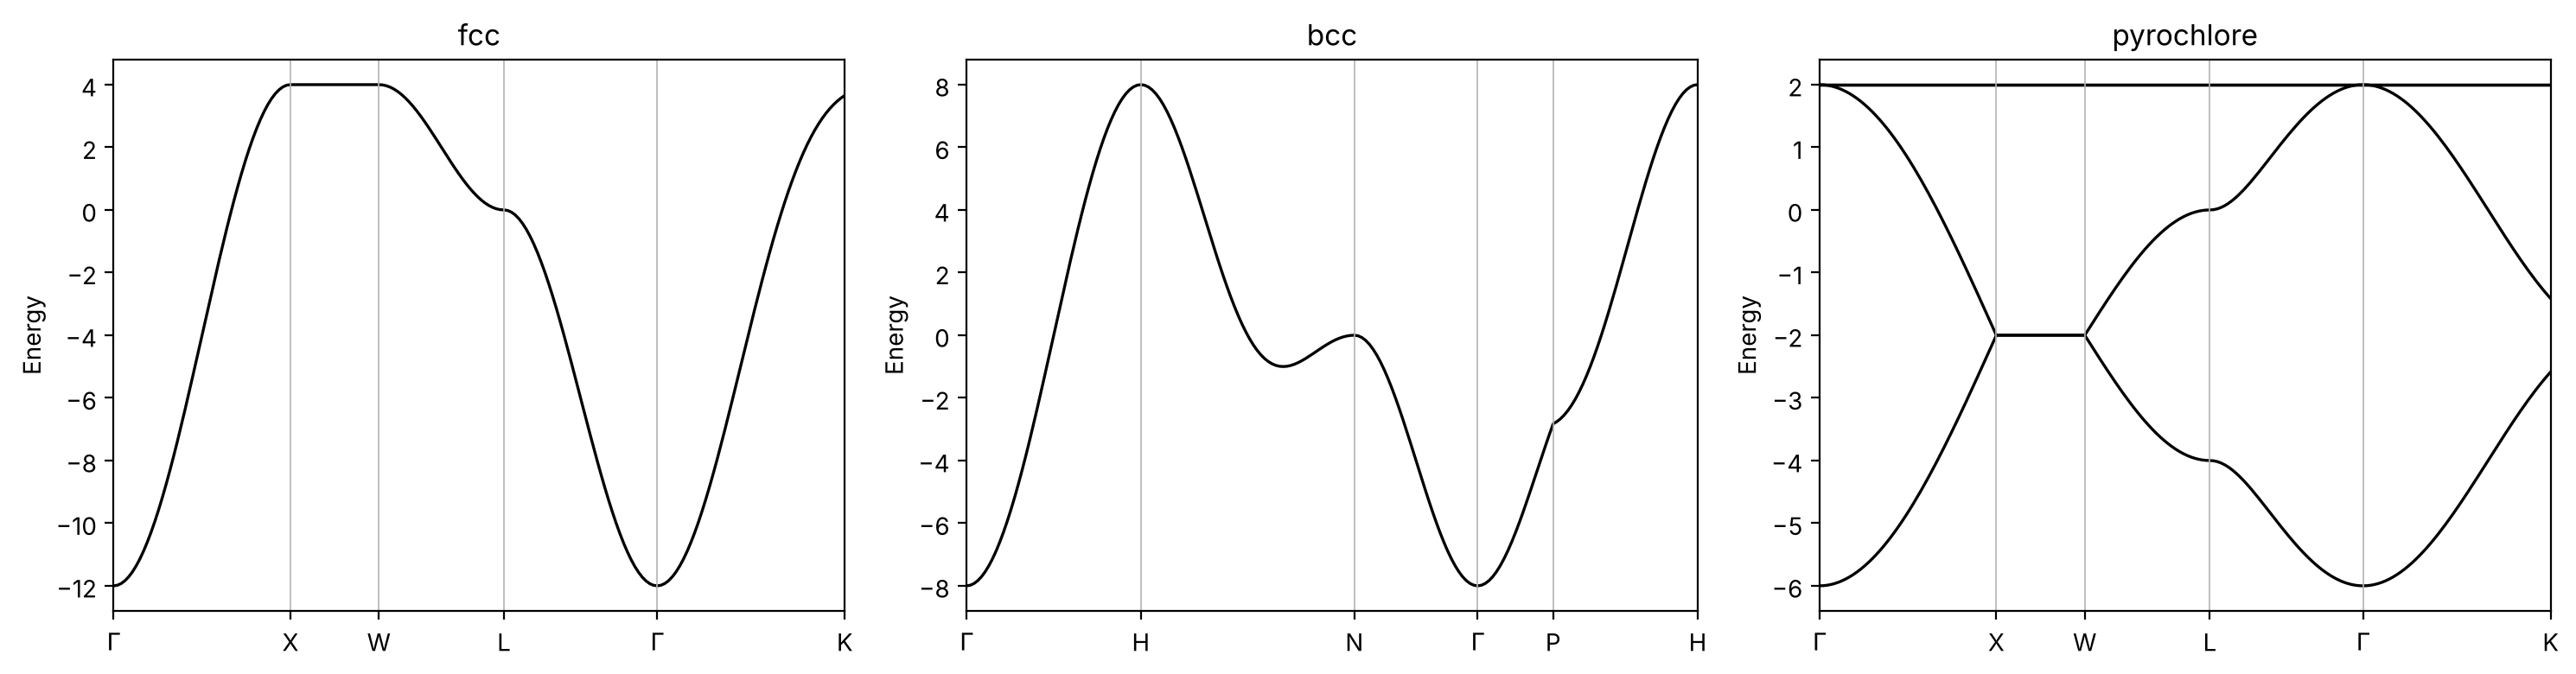

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
M.fcc().plot_bands(ax=axes[0]); M.bcc().plot_bands(ax=axes[1]); M.pyrochlore().plot_bands(ax=axes[2])
plt.tight_layout()

## 6. Bilayer graphene: quadratic touching and a gap with bias

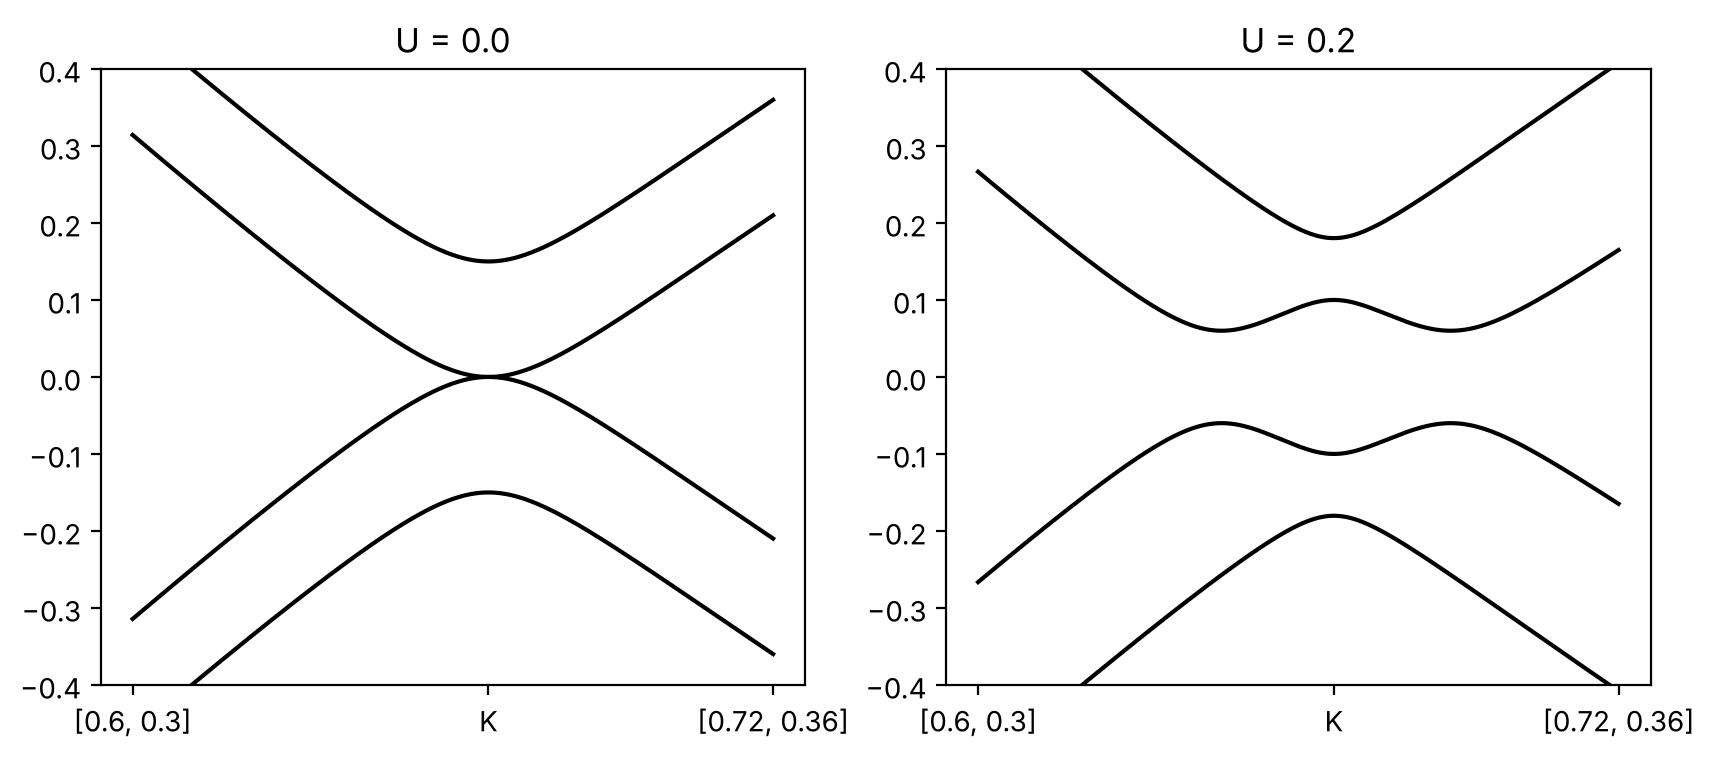

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, U in zip(axes, [0.0, 0.2]):
    m = M.bilayer_graphene(tperp=0.15, U=U)
    p = hf.kpath(m, [[0.6, 0.3], "K", [0.72, 0.36]], n=300)
    b = hf.bands(m, p)
    ax.plot(b.x, b.energies, "k"); ax.set_ylim(-0.4, 0.4); ax.set_title(f"U = {U}")
    ax.set_xticks(p.ticks); ax.set_xticklabels(p.labels)

## Exercises
1. Plot the DOS of the cubic lattice: where are the van Hove kinks?
2. Show that the Lieb flat band carries weight only on the O sites (PDOS).
3. For `M.rashba_square(J=0.5)`, colour bands by `spin_operator('x')`.

---
## Quiz 02: Bands and DOS

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [10]:
quiz = hf.Quiz(2)
quiz.interactive()

In [11]:
quiz.show()

=== Quiz 02: Band structures, density of states and Fermi levels ===

Q1. The bandwidth of the 1D chain E = -2t cos k is
   (a) 4t
   (b) t
   (c) 2t
   (d) 8t

Q2. Graphene's two bands touch linearly at
   (a) everywhere on the zone boundary
   (b) K and K'
   (c) M
   (d) Gamma

Q3. At Gamma, NN graphene (hopping -t) has energies
   (a) -3t, 3t
   (b) -6t, 6t
   (c) -t, t
   (d) 0, 0

Q4. A staggered potential +-Delta on graphene's A/B sites
   (a) opens a gap 2 Delta at K and K'
   (b) creates a flat band
   (c) shifts the Dirac point to Gamma
   (d) does nothing

Q5. The kagome lattice with NN hopping -t has a flat band at
   (a) E = 2t
   (b) E = -2t
   (c) E = -4t
   (d) E = 0

Q6. In 2D, a saddle point of E(k) produces in the DOS a
   (a) logarithmic (van Hove) divergence
   (b) square-root edge
   (c) delta peak
   (d) step

Q7. A flat band shows up in the DOS as
   (a) a gap
   (b) a log divergence
   (c) a linear V shape
   (d) a delta-like peak (broadened by sigma)

Q8. Near

In [12]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0